In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df_jessa = pd.read_feather(
    r"..\code\baseline\datasets\new_train_set_with_sections.feather"
)
df_mimic = pd.read_feather(
    r"..\code\baseline\datasets\mimiciv_cardiology_subset_prediction_25_labels_with_sections.feather"
)

print(f"Jessa: {len(df_jessa)} notes")
print(f"MIMIC: {len(df_mimic)} notes")

Jessa: 11993 notes
MIMIC: 16663 notes


In [ ]:
# label_cols = [col for col in df_jessa.columns if col.startswith("diagnose_")]

label_cols = [
    "diagnose_i480",
    "diagnose_i481",
    "diagnose_i482",
    "diagnose_i483",
    "diagnose_i484",
    "diagnose_i489",
    "diagnose_i501",
    "diagnose_i502",
    "diagnose_i503",
    "diagnose_i504",
    "diagnose_i508",
    "diagnose_i509",
    "diagnose_i69",
    "diagnose_n171819",
    "diagnose_z8673",
    "diagnose_i10",
    "diagnose_i11",
    "diagnose_i12",
    "diagnose_i13",
    "diagnose_e10",
    "diagnose_e11",
]

# --- Basic dataset stats ---
jessa_dist = df_jessa[label_cols].mean()
mimic_dist = df_mimic[label_cols].mean()

jessa_n_notes = len(df_jessa)
mimic_n_notes = len(df_mimic)

jessa_n_codes = df_jessa[label_cols].sum().sum()
mimic_n_codes = df_mimic[label_cols].sum().sum()

jessa_avg_codes = df_jessa[label_cols].sum(axis=1).mean()
mimic_avg_codes = df_mimic[label_cols].sum(axis=1).mean()

stats_df = pd.DataFrame(
    {
        "metric": [
            "Number of notes",
            "Number of positive labels",
            "Avg labels per note",
        ],
        "Jessa": [jessa_n_notes, jessa_n_codes, jessa_avg_codes],
        "MIMIC-IV": [mimic_n_notes, mimic_n_codes, mimic_avg_codes],
    }
)

stats_long = stats_df.melt(id_vars="metric", var_name="dataset", value_name="value")

# Combine into one DataFrame
df_plot = pd.DataFrame(
    {"label": label_cols, "Jessa": jessa_dist.values, "MIMIC": mimic_dist.values}
)

# Convert to long format
df_long = df_plot.melt(id_vars="label", var_name="dataset", value_name="prevalence")


def get_category(label):
    if "i48" in label:
        return "Atrial fibrillation"
    elif "i50" in label:
        return "Heart failure"
    elif label.startswith("diagnose_i1"):
        return "Hypertension"
    elif label.startswith("diagnose_e1"):
        return "Diabetes"
    else:
        return "Other"


df_plot["category"] = df_plot["label"].apply(get_category)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

stats_table = pd.DataFrame(
    {
        "Metric": [
            "Number of notes",
            "Number of positive labels",
            "Average labels per note",
        ],
        "Jessa": [jessa_n_notes, jessa_n_codes, round(jessa_avg_codes, 2)],
        "MIMIC-IV": [mimic_n_notes, mimic_n_codes, round(mimic_avg_codes, 2)],
    }
)
print(stats_table)


# palette = {
#     "Jessa": sns.color_palette("colorblind")[0],
#     "MIMIC-IV": sns.color_palette("colorblind")[3]
# }

                      Metric     Jessa  MIMIC-IV
0            Number of notes  11993.00  16663.00
1  Number of positive labels  25038.00  45342.00
2    Average labels per note      2.09      2.72


C:\Users\guest5\AppData\Local\Temp\ipykernel_21652\4085590959.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


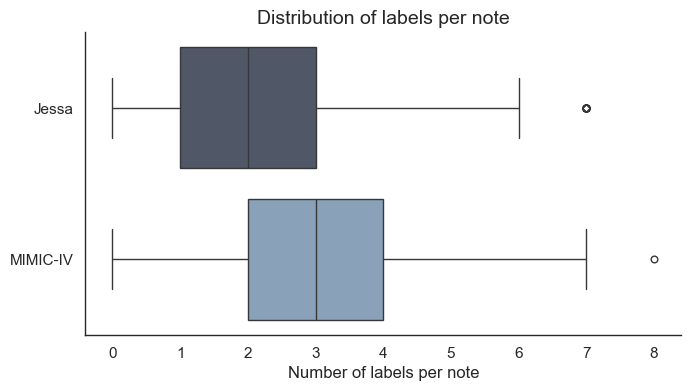

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="white", context="paper")

# Compute labels per note
df_jessa["n_labels"] = df_jessa[label_cols].sum(axis=1)
df_mimic["n_labels"] = df_mimic[label_cols].sum(axis=1)

# Combine
df_box = pd.concat(
    [
        df_jessa[["n_labels"]].assign(dataset="Jessa"),
        df_mimic[["n_labels"]].assign(dataset="MIMIC-IV"),
    ]
)

plt.figure(figsize=(7, 4))

ax = sns.boxplot(data=df_box, y="dataset", x="n_labels", palette=["#4C566A", "#81A1C1"])

ax.set_title("Distribution of labels per note", fontsize=14)
ax.set_xlabel("Number of labels per note", fontsize=12)
ax.set_ylabel("")

ax.tick_params(axis="both", labelsize=11)

sns.despine()
plt.tight_layout()
plt.show()

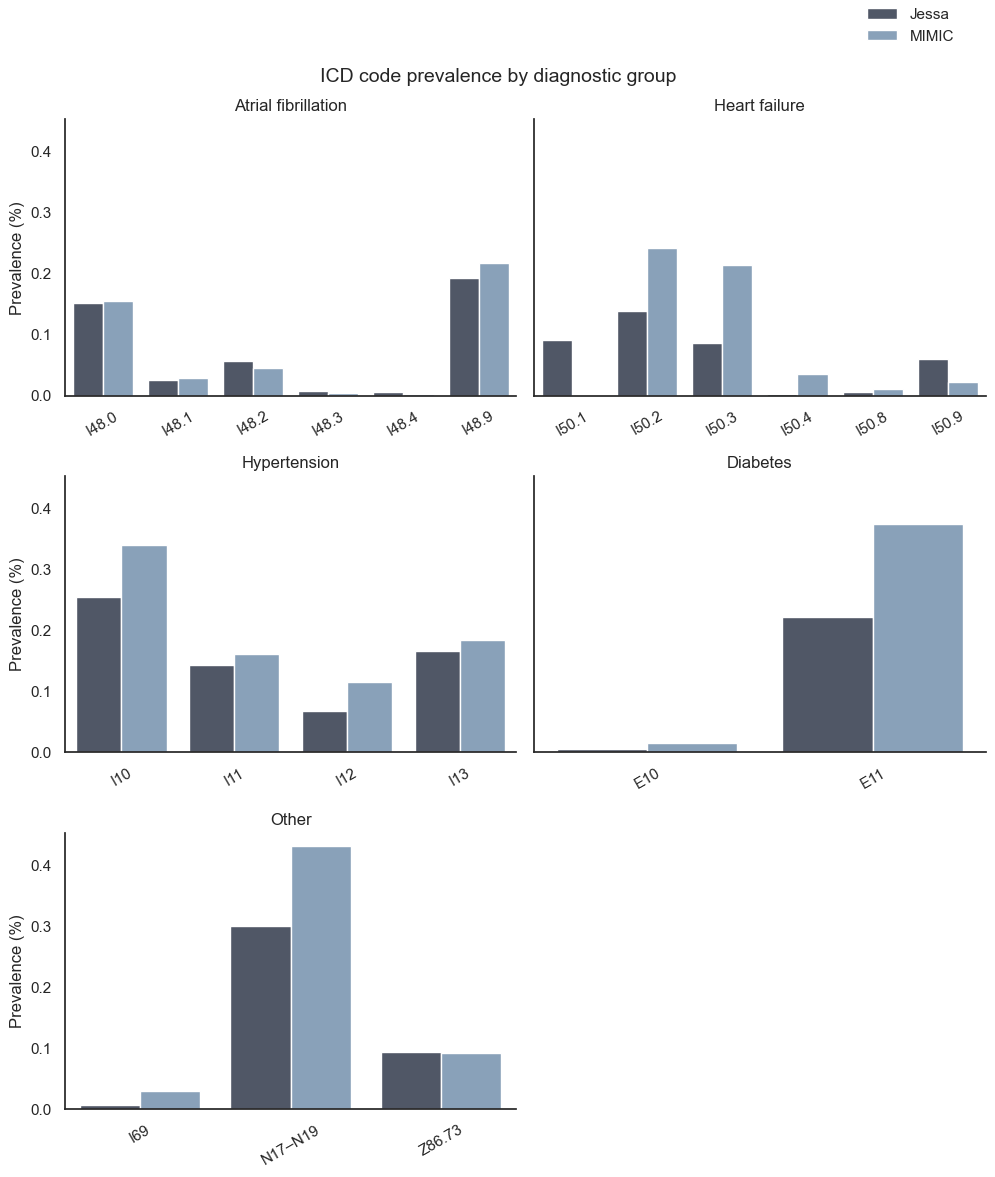

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Theme + palette
# -----------------------------
sns.set_theme(style="white", palette=["#4C566A", "#81A1C1"])

# -----------------------------
# ICD label mapping
# -----------------------------
label_mapping = {
    "diagnose_i480": "I48.0",
    "diagnose_i481": "I48.1",
    "diagnose_i482": "I48.2",
    "diagnose_i483": "I48.3",
    "diagnose_i484": "I48.4",
    "diagnose_i489": "I48.9",
    "diagnose_i501": "I50.1",
    "diagnose_i502": "I50.2",
    "diagnose_i503": "I50.3",
    "diagnose_i504": "I50.4",
    "diagnose_i508": "I50.8",
    "diagnose_i509": "I50.9",
    "diagnose_i69": "I69",
    "diagnose_n171819": "N17–N19",
    "diagnose_z8673": "Z86.73",
    "diagnose_i10": "I10",
    "diagnose_i11": "I11",
    "diagnose_i12": "I12",
    "diagnose_i13": "I13",
    "diagnose_e10": "E10",
    "diagnose_e11": "E11",
}

# -----------------------------
# Apply mapping
# -----------------------------
df_plot["icd_label"] = df_plot["label"].map(label_mapping)

# Merge with long format
data = df_long.merge(df_plot[["label", "category", "icd_label"]], on="label")

# -----------------------------
# Category order (force "Other" last)
# -----------------------------
category_order = [
    "Atrial fibrillation",
    "Heart failure",
    "Hypertension",
    "Diabetes",
    "Other",
]

# -----------------------------
# Create plot
# -----------------------------
g = sns.catplot(
    data=data,
    x="icd_label",
    y="prevalence",
    hue="dataset",
    col="category",
    col_order=category_order,
    kind="bar",
    col_wrap=2,
    height=3.8,
    aspect=1.2,
    sharex=False,
    legend=True,
)

# -----------------------------
# Aesthetics
# -----------------------------
for ax in g.axes.flat:
    ax.set_xlabel("")
    ax.set_ylabel("Prevalence (%)")
    ax.tick_params(axis="x", rotation=30)
    sns.despine(ax=ax)

# Clean facet titles
for ax, cat in zip(g.axes.flat, category_order):
    ax.set_title(cat)

# Legend formatting
g._legend.set_title("")
g._legend.set_bbox_to_anchor((0.9, 1.01))
g._legend.set_loc("center")
g._legend.set_frame_on(False)

# Title
g.fig.suptitle("ICD code prevalence by diagnostic group", fontsize=14)
plt.tight_layout()
plt.show()

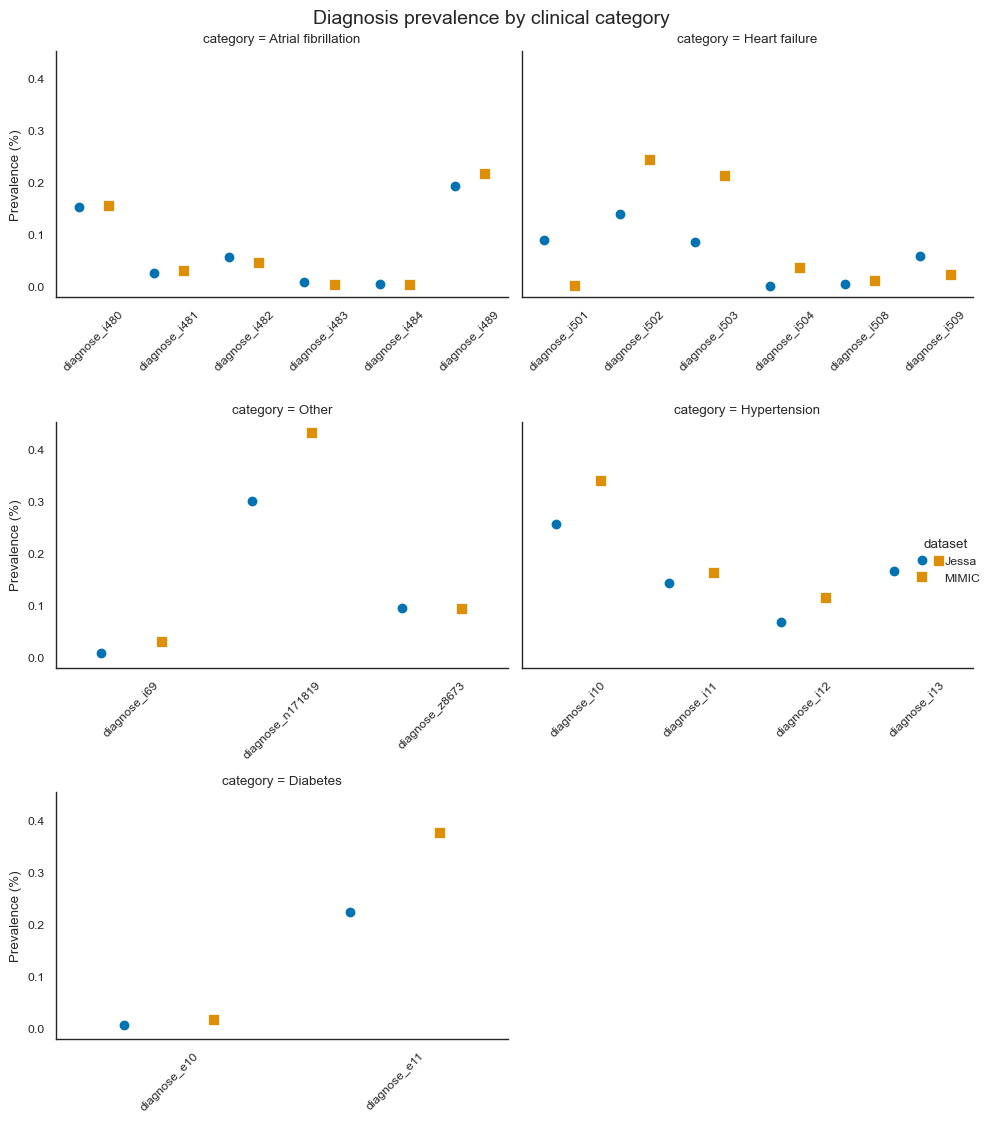

In [ ]:
g = sns.catplot(
    data=df_long.merge(df_plot[["label", "category"]], on="label"),
    x="label",
    y="prevalence",
    hue="dataset",
    col="category",
    kind="point",
    col_wrap=2,
    height=3.8,
    aspect=1.2,
    sharex=False,
    dodge=0.4,
    markers=["o", "s"],
    linestyles="",
)

for ax in g.axes.flat:
    ax.set_xlabel("")
    ax.set_ylabel("Prevalence (%)")
    ax.tick_params(axis="x", rotation=45)
    sns.despine(ax=ax)

g.fig.suptitle("Diagnosis prevalence by clinical category", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))
sns.barplot(data=df_long, x="label", y="prevalence", hue="dataset")

plt.xticks(rotation=90)
plt.title("Label prevalence comparison (Jessa vs MIMIC)")
plt.tight_layout()
plt.show()

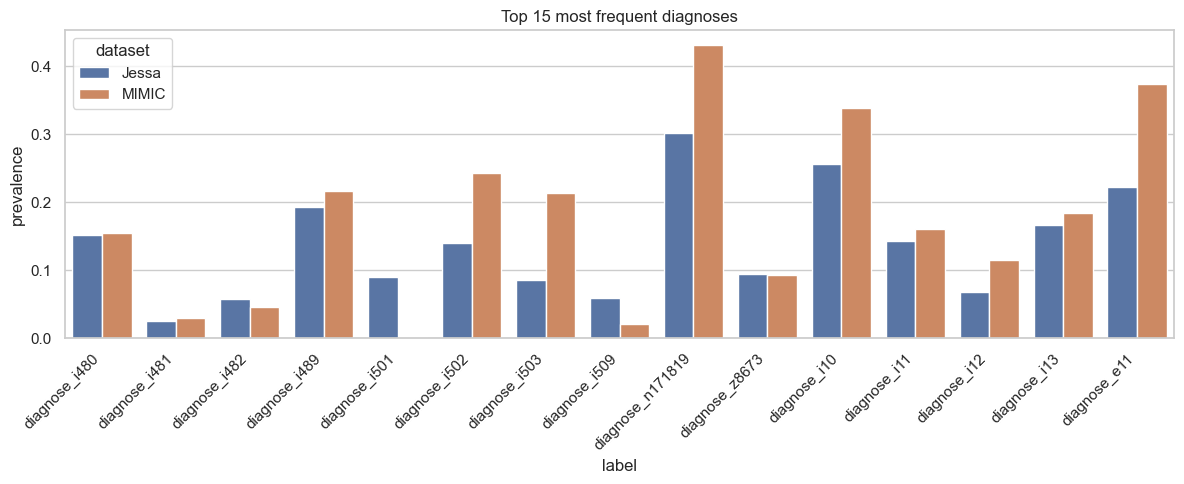

In [ ]:
top_k = 15

top_labels = jessa_dist.sort_values(ascending=False).head(top_k).index
df_top = df_long[df_long["label"].isin(top_labels)]

plt.figure(figsize=(12, 5))
sns.barplot(data=df_top, x="label", y="prevalence", hue="dataset")

plt.xticks(rotation=45, ha="right")
plt.title(f"Top {top_k} most frequent diagnoses")
plt.tight_layout()
plt.show()

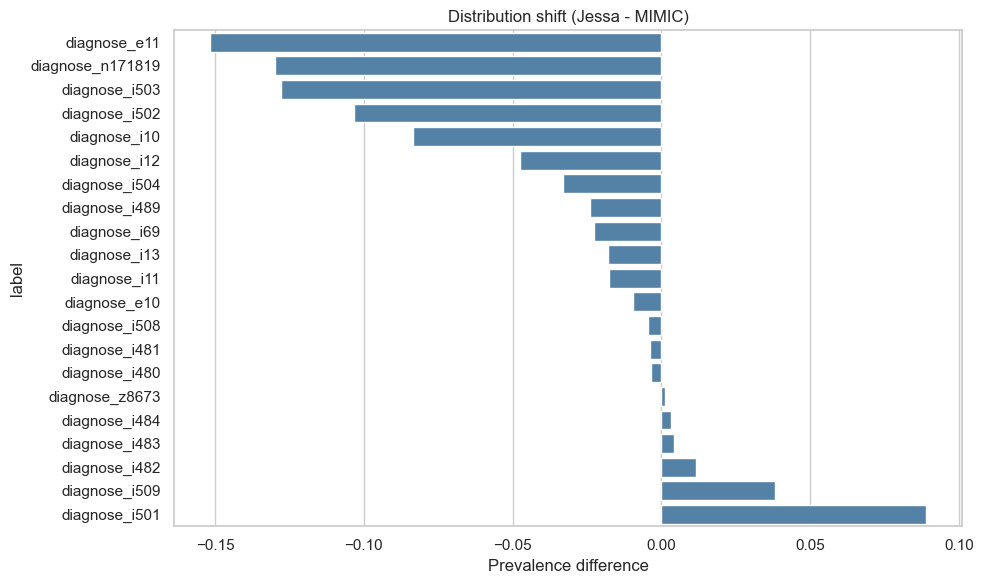

In [ ]:
df_plot["difference"] = df_plot["Jessa"] - df_plot["MIMIC"]
df_diff = df_plot.sort_values("difference")

plt.figure(figsize=(10, 6))
sns.barplot(data=df_diff, y="label", x="difference", color="steelblue")

plt.title("Distribution shift (Jessa - MIMIC)")
plt.xlabel("Prevalence difference")
plt.tight_layout()
plt.show()